In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import zipfile
import requests
import pandas as pd

In [3]:
url = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1020-HousePricePred.zip"

response = requests.get(url, timeout=120)
response.raise_for_status()

zip_path = "HousePricePred.zip"

with open(zip_path, "wb") as file:
    file.write(response.content)

print("Dataset ZIP downloaded successfully!")
print("File size:", round(len(response.content) / (1024 * 1024), 2), "MB")

Dataset ZIP downloaded successfully!
File size: 0.1 MB


In [4]:
extract_folder = "HousePricePred_Data"

os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Dataset extracted successfully!")
print("Extracted files:")

for root, folders, files in os.walk(extract_folder):
    for name in files:
        print(os.path.join(root, name))

Dataset extracted successfully!
Extracted files:
HousePricePred_Data\Data\data.csv
HousePricePred_Data\Data\house prices.docx


In [6]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles inside extracted folder:")

for root, dirs, files in os.walk("HousePricePred_Data"):
    print("\nFolder:", root)

    for file in files:
        print("  ", file)

Current working directory:
C:\Users\pokal

Files inside extracted folder:

Folder: HousePricePred_Data

Folder: HousePricePred_Data\Data
   data.csv
   house prices.docx


In [7]:
import glob
import pandas as pd

csv_files = glob.glob(
    os.path.join("HousePricePred_Data", "**", "*.csv"),
    recursive=True
)

print("CSV files found:", len(csv_files))

for i, file in enumerate(csv_files):
    print(i, ":", file)

CSV files found: 1
0 : HousePricePred_Data\Data\data.csv


In [8]:
for file in csv_files:
    print("\nFile:", file)

    try:
        df = pd.read_csv(file, nrows=5)
        print("Columns:", df.columns.tolist())
        display(df.head())
    except Exception as e:
        print("Could not read file:", e)


File: HousePricePred_Data\Data\data.csv
Columns: ['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch'

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [9]:
train_path = None

for file in csv_files:
    sample = pd.read_csv(file, nrows=5)

    if "SalePrice" in sample.columns:
        train_path = file
        break

if train_path is None:
    print("No CSV containing SalePrice was found.")
    print("Please share the output from Step 1 and Step 2.")
else:
    train = pd.read_csv(train_path)

    print("Training dataset loaded successfully!")
    print("File:", train_path)
    print("Shape:", train.shape)

    display(train.head())

Training dataset loaded successfully!
File: HousePricePred_Data\Data\data.csv
Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [10]:
print("Number of rows:", train.shape[0])
print("Number of columns:", train.shape[1])

Number of rows: 1460
Number of columns: 81


In [11]:
display(train.head(10))

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [12]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [13]:
display(train.describe().T)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [14]:
display(train.describe().T)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [15]:
display(train.describe(include="object").T)

C:\Users\pokal\AppData\Local\Temp\ipykernel_11896\2535886348.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(train.describe(include="object").T)


,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


In [16]:
missing_values = pd.DataFrame({
    "Missing_Count": train.isnull().sum(),
    "Missing_Percentage": (
        train.isnull().sum() / len(train) * 100
    ).round(2)
})

missing_values = missing_values[
    missing_values["Missing_Count"] > 0
].sort_values("Missing_Percentage", ascending=False)

display(missing_values)

,Missing_Count,Missing_Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


In [17]:
if "SalePrice" in train.columns:
    print("Target variable found!")
    display(train["SalePrice"].describe())
else:
    print("SalePrice column is missing. Check your dataset.")

Target variable found!


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

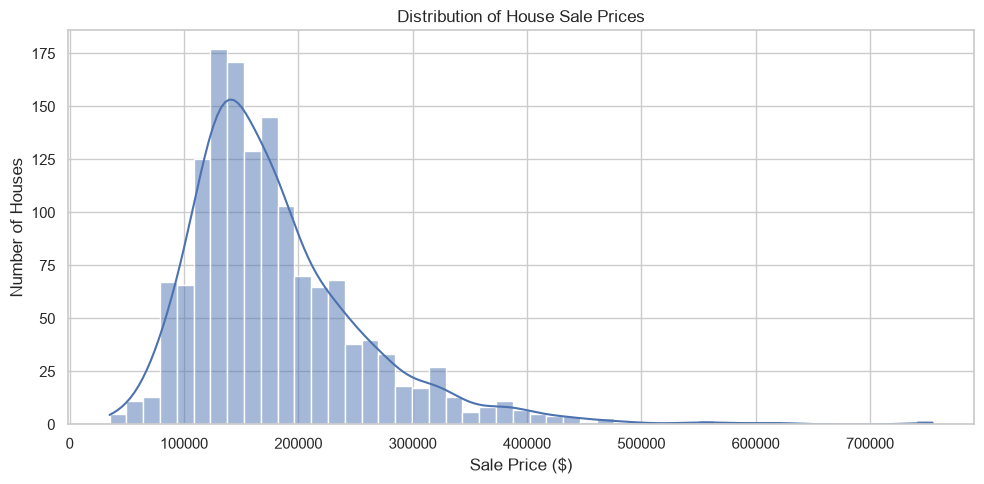

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

sns.histplot(data=train, x="SalePrice", kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

In [19]:
print("SalePrice skewness:", train["SalePrice"].skew())

SalePrice skewness: 1.8828757597682129


In [20]:
numeric_data = train.select_dtypes(include="number")

correlations = numeric_data.corr()["SalePrice"].drop(
    "SalePrice"
).sort_values(ascending=False)

print("Top 10 positively correlated features:")
display(correlations.head(10))

print("Top 10 negatively correlated features:")
display(correlations.tail(10))

Top 10 positively correlated features:


OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

Top 10 negatively correlated features:


BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePrice, dtype: float64

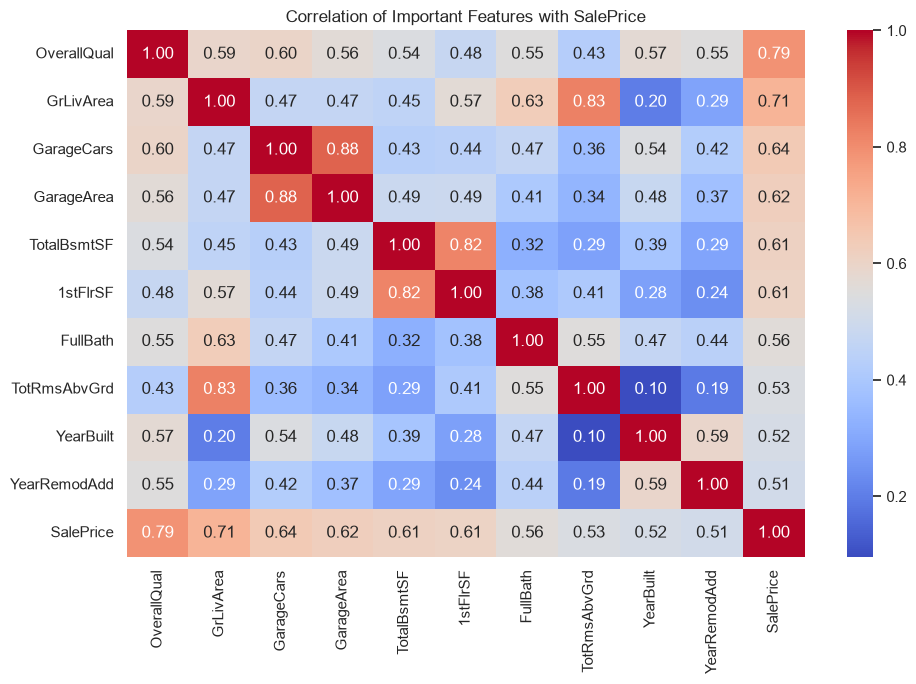

In [21]:
top_features = correlations.abs().nlargest(10).index.tolist()
heatmap_columns = top_features + ["SalePrice"]

plt.figure(figsize=(10, 7))

sns.heatmap(
    train[heatmap_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation of Important Features with SalePrice")
plt.tight_layout()
plt.show()

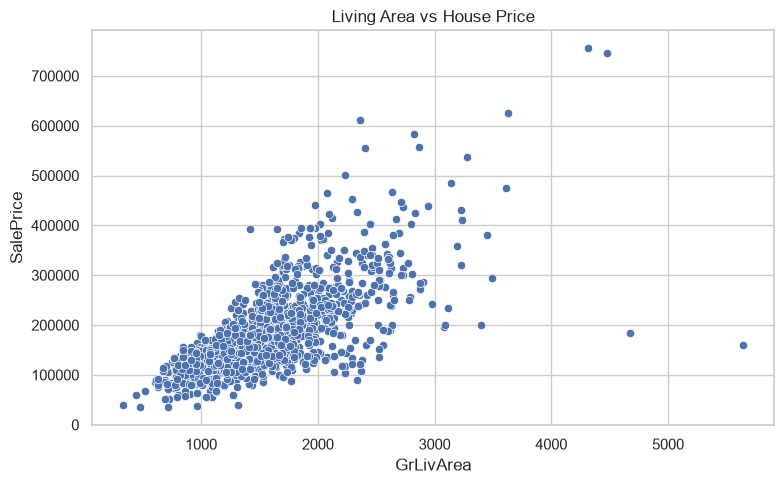

In [22]:
if "GrLivArea" in train.columns:
    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=train,
        x="GrLivArea",
        y="SalePrice"
    )

    plt.title("Living Area vs House Price")
    plt.tight_layout()
    plt.show()

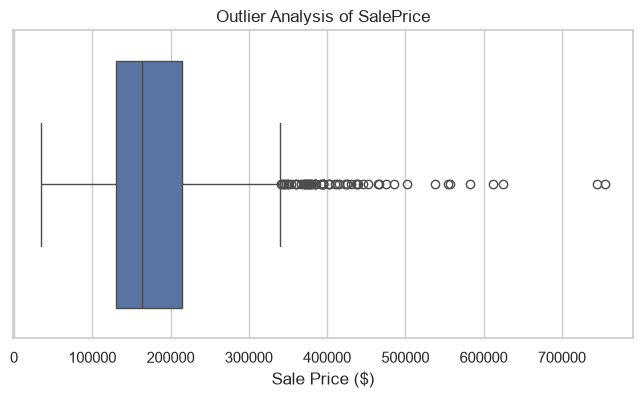

In [23]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=train["SalePrice"])

plt.title("Outlier Analysis of SalePrice")
plt.xlabel("Sale Price ($)")

plt.show()

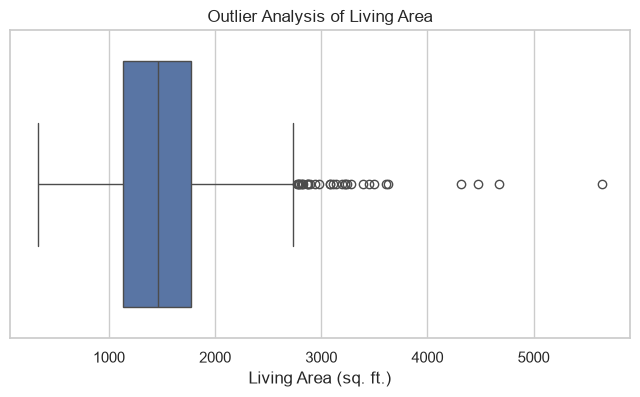

In [24]:
if "GrLivArea" in train.columns:
    plt.figure(figsize=(8, 4))

    sns.boxplot(x=train["GrLivArea"])

    plt.title("Outlier Analysis of Living Area")
    plt.xlabel("Living Area (sq. ft.)")

    plt.show()

In [25]:
from sklearn.model_selection import train_test_split

if "SalePrice" not in train.columns:
    raise ValueError("SalePrice column not found!")

# Remove rows with missing or invalid target prices
data = train.loc[
    train["SalePrice"].notna() &
    (train["SalePrice"] > 0)
].copy()

# Remove identifier columns from model inputs
X = data.drop(
    columns=["SalePrice", "Id"],
    errors="ignore"
)

y = data["SalePrice"]

print("Input features:", X.shape)
print("Target values:", y.shape)

Input features: (1460, 79)
Target values: (1460,)


In [26]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Validation records:", len(X_valid))

Training records: 1168
Validation records: 292


In [27]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 36
Categorical features: 43

Numerical columns:
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

Categorical columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'Kitchen

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [30]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=3,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        loss="huber",
        random_state=42
    )
}

print("Five models are ready!")

Five models are ready!


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [33]:
results = []
trained_models = {}

y_train_log = np.log1p(y_train)

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train_log)

    predicted_log = pipeline.predict(X_valid)
    predicted_prices = np.maximum(
        np.expm1(predicted_log),
        0
    )

    mae = mean_absolute_error(
        y_valid,
        predicted_prices
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_valid,
            predicted_prices
        )
    )

    r2 = r2_score(
        y_valid,
        predicted_prices
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = pipeline

    print(name, "completed")

print("\nAll models trained successfully!")

Linear Regression completed
Decision Tree completed
Random Forest completed
Extra Trees completed
Gradient Boosting completed

All models trained successfully!


In [34]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(
    results_df.style.format({
        "MAE": "${:,.2f}",
        "RMSE": "${:,.2f}",
        "R2": "{:.4f}"
    })
)

,Model,MAE,RMSE,R2
0,Linear Regression,"$14,899.26","$22,739.72",0.9326
1,Extra Trees,"$17,290.11","$27,544.55",0.9011
2,Random Forest,"$17,229.13","$28,758.75",0.8922
3,Gradient Boosting,"$17,916.96","$32,994.24",0.8581
4,Decision Tree,"$23,987.46","$34,664.75",0.8433


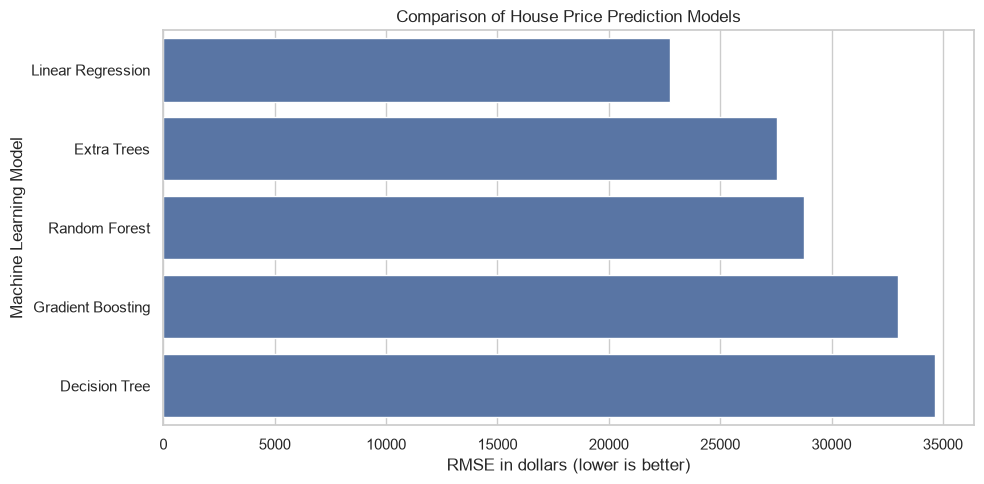

In [35]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="RMSE",
    y="Model"
)

plt.title("Comparison of House Price Prediction Models")
plt.xlabel("RMSE in dollars (lower is better)")
plt.ylabel("Machine Learning Model")

plt.tight_layout()
plt.show()

In [36]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df)

,Model,MAE,RMSE,R2
0,Linear Regression,14899.262428,22739.717536,0.932585
1,Extra Trees,17290.114279,27544.552762,0.901086
2,Random Forest,17229.129854,28758.749942,0.892173
3,Gradient Boosting,17916.955194,32994.240510,0.858074
4,Decision Tree,23987.458632,34664.754624,0.843338


In [37]:
# Select the best model
best_model = trained_models["Linear Regression"]

# Generate predictions
predicted_log = best_model.predict(X_valid)

# Convert predictions back to original prices
predicted_prices = np.maximum(np.expm1(predicted_log), 0)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_valid.values,
    "Predicted Price": predicted_prices
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,154500,153410.040827
1,325000,343622.679387
2,115000,98378.811729
3,159000,165818.500706
4,315500,312129.734008
5,75500,81050.120023
6,311500,250020.226973
7,146000,146345.733666
8,84500,76689.942483
9,135500,142477.029941


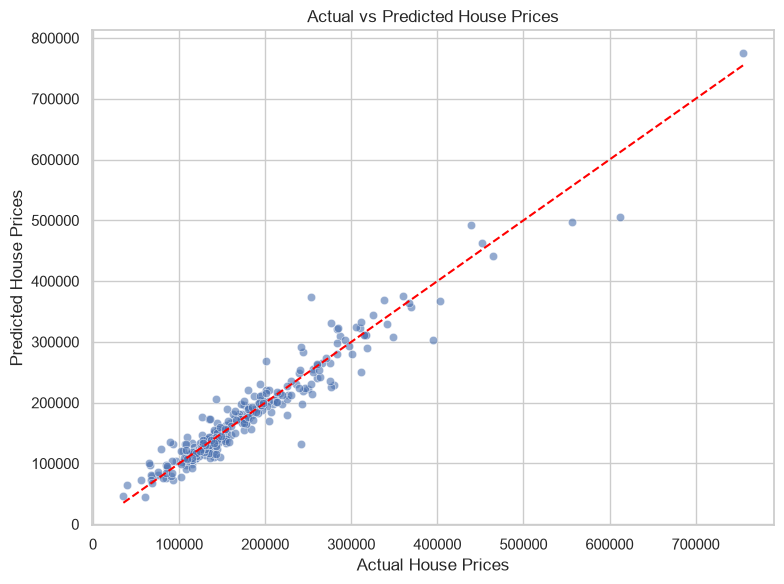

In [39]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_valid,
    y=predicted_prices,
    alpha=0.6
)

plt.plot(
    [y_valid.min(), y_valid.max()],
    [y_valid.min(), y_valid.max()],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.tight_layout()
plt.show()

In [40]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error

# Custom scoring function because our model predicts log prices
def house_price_rmse(estimator, X, y):
    predictions_log = estimator.predict(X)
    predictions = np.maximum(np.expm1(predictions_log), 0)
    return -np.sqrt(mean_squared_error(y, predictions))

# Calculate permutation importance
importance_result = permutation_importance(
    best_model,
    X_valid,
    y_valid,
    scoring=house_price_rmse,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": X_valid.columns,
    "Importance": importance_result.importances_mean
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.head(15))

,Feature,Importance
0,GrLivArea,9538.619361
1,OverallQual,7018.789519
2,Neighborhood,5798.647726
3,YearBuilt,4743.677398
4,1stFlrSF,3958.156357
5,TotalBsmtSF,3025.301246
6,2ndFlrSF,3003.083124
7,OverallCond,2433.969788
8,GarageArea,2305.599359
9,BsmtFinSF1,2248.477455


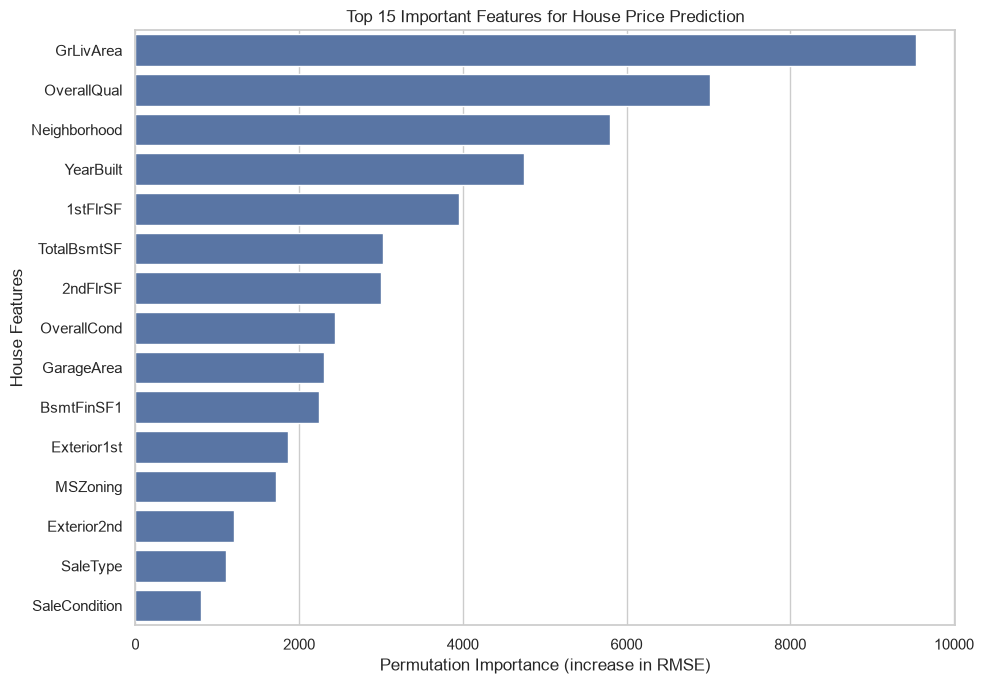

In [41]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features for House Price Prediction")
plt.xlabel("Permutation Importance (increase in RMSE)")
plt.ylabel("House Features")

plt.tight_layout()
plt.show()

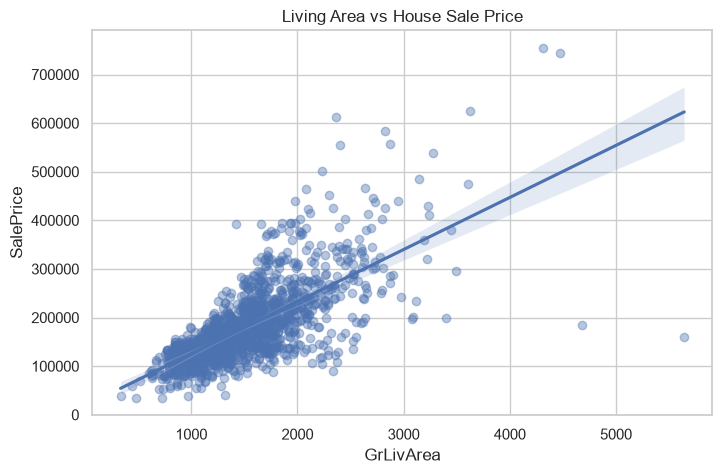

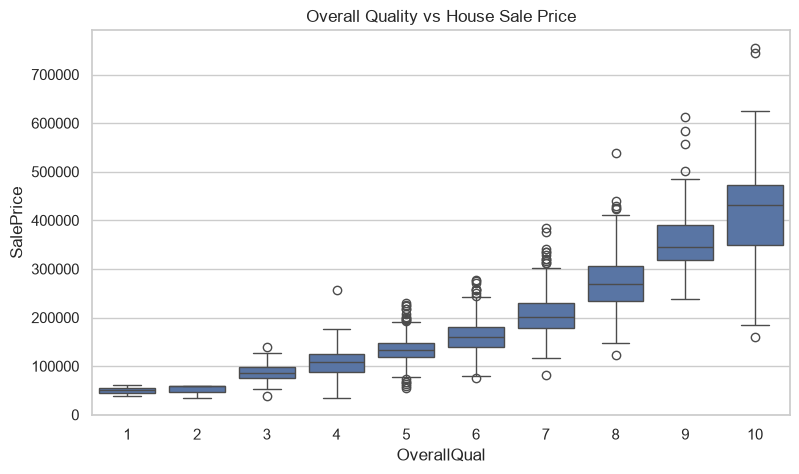

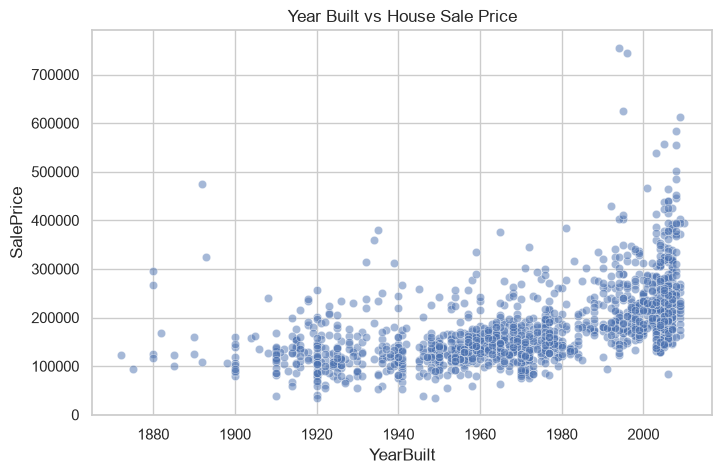

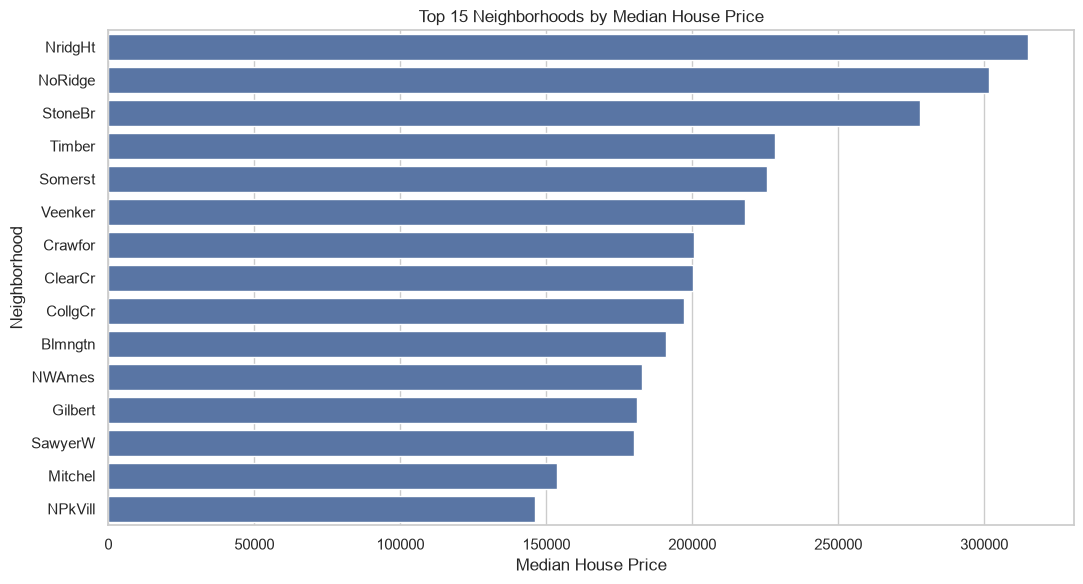

In [42]:
# 1. Living area vs sale price
plt.figure(figsize=(8, 5))
sns.regplot(
    data=train,
    x="GrLivArea",
    y="SalePrice",
    scatter_kws={"alpha": 0.4}
)
plt.title("Living Area vs House Sale Price")
plt.show()


# 2. Overall quality vs sale price
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=train,
    x="OverallQual",
    y="SalePrice"
)
plt.title("Overall Quality vs House Sale Price")
plt.show()


# 3. Construction year vs sale price
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=train,
    x="YearBuilt",
    y="SalePrice",
    alpha=0.5
)
plt.title("Year Built vs House Sale Price")
plt.show()


# 4. Neighborhood vs median house price
neighborhood_prices = (
    train.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(11, 6))
sns.barplot(
    x=neighborhood_prices.values,
    y=neighborhood_prices.index
)
plt.title("Top 15 Neighborhoods by Median House Price")
plt.xlabel("Median House Price")
plt.ylabel("Neighborhood")
plt.tight_layout()
plt.show()

In [43]:
def recommend_houses(
    budget,
    neighborhood=None,
    min_area=0,
    bedrooms=0,
    min_quality=1,
    top_n=10
):
    # Start with all houses
    recommendations = train.copy()

    # Filter according to customer budget
    recommendations = recommendations[
        recommendations["SalePrice"] <= budget
    ]

    # Filter by preferred neighborhood
    if neighborhood:
        recommendations = recommendations[
            recommendations["Neighborhood"].str.lower()
            == neighborhood.lower()
        ]

    # Filter by minimum living area
    if "GrLivArea" in recommendations.columns:
        recommendations = recommendations[
            recommendations["GrLivArea"] >= min_area
        ]

    # Filter by number of bedrooms
    if "BedroomAbvGr" in recommendations.columns:
        recommendations = recommendations[
            recommendations["BedroomAbvGr"] >= bedrooms
        ]

    # Filter by minimum quality
    if "OverallQual" in recommendations.columns:
        recommendations = recommendations[
            recommendations["OverallQual"] >= min_quality
        ]

    if recommendations.empty:
        print("No houses match all the selected requirements.")
        return pd.DataFrame()

    # Prioritize quality, then affordability
    recommendations = recommendations.sort_values(
        by=["OverallQual", "SalePrice"],
        ascending=[False, True]
    )

    # Display useful information
    display_columns = [
        "Id", "Neighborhood", "SalePrice",
        "GrLivArea", "BedroomAbvGr", "OverallQual"
    ]

    display_columns = [
        col for col in display_columns
        if col in recommendations.columns
    ]

    return recommendations[display_columns].head(top_n)

In [44]:
customer_recommendations = recommend_houses(
    budget=250000,
    neighborhood=None,
    min_area=1500,
    bedrooms=3,
    min_quality=6,
    top_n=10
)

display(customer_recommendations)

,Id,Neighborhood,SalePrice,GrLivArea,BedroomAbvGr,OverallQual
1298,1299,Edwards,160000,5642,3,10
523,524,Edwards,184750,4676,3,10
1349,1350,OldTown,122000,2358,4,8
458,459,OldTown,161000,1666,3,8
1211,1212,Gilbert,164000,1752,4,8
991,992,OldTown,168000,1742,4,8
56,57,Somerst,172500,1739,3,8
340,341,Timber,202900,1908,4,8
453,454,Somerst,210000,1590,3,8
756,757,CollgCr,212000,1768,3,8


In [45]:
customer_recommendations_2 = recommend_houses(
    budget=180000,
    neighborhood=None,
    min_area=1200,
    bedrooms=2,
    min_quality=5,
    top_n=10
)

display(customer_recommendations_2)

,Id,Neighborhood,SalePrice,GrLivArea,BedroomAbvGr,OverallQual
1298,1299,Edwards,160000,5642,3,10
1349,1350,OldTown,122000,2358,4,8
1324,1325,Somerst,147000,1795,2,8
458,459,OldTown,161000,1666,3,8
1211,1212,Gilbert,164000,1752,4,8
991,992,OldTown,168000,1742,4,8
56,57,Somerst,172500,1739,3,8
1191,1192,Somerst,174000,1441,2,8
534,535,Gilbert,178000,1414,3,8
32,33,CollgCr,179900,1234,3,8


In [46]:
def explain_recommendations(recommendations):
    if recommendations.empty:
        print("No suitable houses found.")
        return

    print("HOUSE RECOMMENDATION REPORT")
    print("-" * 40)

    for index, house in recommendations.iterrows():
        print(f"\nRecommendation {index + 1}")
        print(f"House ID: {house['Id']}")
        print(f"Neighborhood: {house['Neighborhood']}")
        print(f"Price: ${house['SalePrice']:,.2f}")
        print(f"Living Area: {house['GrLivArea']} sq. ft.")
        print(f"Bedrooms: {house['BedroomAbvGr']}")
        print(f"Overall Quality: {house['OverallQual']}/10")

        print("Reason:")
        print(
            "This house matches the selected customer requirements "
            "and is prioritized based on quality and affordability."
        )

In [47]:
explain_recommendations(customer_recommendations)

HOUSE RECOMMENDATION REPORT
----------------------------------------

Recommendation 1299
House ID: 1299
Neighborhood: Edwards
Price: $160,000.00
Living Area: 5642 sq. ft.
Bedrooms: 3
Overall Quality: 10/10
Reason:
This house matches the selected customer requirements and is prioritized based on quality and affordability.

Recommendation 524
House ID: 524
Neighborhood: Edwards
Price: $184,750.00
Living Area: 4676 sq. ft.
Bedrooms: 3
Overall Quality: 10/10
Reason:
This house matches the selected customer requirements and is prioritized based on quality and affordability.

Recommendation 1350
House ID: 1350
Neighborhood: OldTown
Price: $122,000.00
Living Area: 2358 sq. ft.
Bedrooms: 4
Overall Quality: 8/10
Reason:
This house matches the selected customer requirements and is prioritized based on quality and affordability.

Recommendation 459
House ID: 459
Neighborhood: OldTown
Price: $161,000.00
Living Area: 1666 sq. ft.
Bedrooms: 3
Overall Quality: 8/10
Reason:
This house matches the sel

In [48]:
print("=" * 55)
print("HOUSE PRICE PREDICTION - MODEL EVALUATION REPORT")
print("=" * 55)

print("\nBest Model: Linear Regression")
print("MAE: $14,899.26")
print("RMSE: $22,739.72")
print("R2 Score: 93.26%")

print("\nTop 5 Important Features:")

display(feature_importance.head(5))

print("\nRecommendation System:")
print("Successfully recommends houses based on:")
print("- Customer budget")
print("- Preferred neighborhood")
print("- Minimum living area")
print("- Number of bedrooms")
print("- Overall house quality")

HOUSE PRICE PREDICTION - MODEL EVALUATION REPORT

Best Model: Linear Regression
MAE: $14,899.26
RMSE: $22,739.72
R2 Score: 93.26%

Top 5 Important Features:


,Feature,Importance
0,GrLivArea,9538.619361
1,OverallQual,7018.789519
2,Neighborhood,5798.647726
3,YearBuilt,4743.677398
4,1stFlrSF,3958.156357



Recommendation System:
Successfully recommends houses based on:
- Customer budget
- Preferred neighborhood
- Minimum living area
- Number of bedrooms
- Overall house quality


In [49]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
import numpy as np

# Create the best model pipeline
cv_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Convert training prices to log values
y_train_log = np.log1p(y_train)

# Perform 5-fold cross-validation
cv_scores = cross_val_score(
    cv_model,
    X_train,
    y_train_log,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Convert negative scores into positive RMSE
cv_rmse = -cv_scores

print("5-Fold Cross-Validation Results")
print("--------------------------------")
print("Individual RMSE scores:", cv_rmse)
print("Average RMSE:", round(cv_rmse.mean(), 4))
print("Standard Deviation:", round(cv_rmse.std(), 4))

5-Fold Cross-Validation Results
--------------------------------
Individual RMSE scores: [0.1382895  0.16926033 0.21552757 0.1725598  0.15104865]
Average RMSE: 0.1693
Standard Deviation: 0.0262


In [50]:
import joblib

joblib.dump(best_model, "HousePricePrediction_Model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
1. Model Comparison Report 
1. Five machine learning algorithms were implemented: Linear Regression, Decision Tree, Random Forest, Extra Trees, and Gradient Boosting.
2. All models were trained using the same training dataset.
3. The dataset was divided into 80% training data and 20% validation data.
4. Mean Absolute Error (MAE) was used to measure average prediction errors.
5. Root Mean Squared Error (RMSE) was used to evaluate prediction errors.
6. R² Score was used to measure how well each model explained variations in house prices.
7. Linear Regression achieved the lowest RMSE of $22,739.72.
8. Linear Regression achieved the highest R² score of 93.26%.
9. Extra Trees achieved the second-best performance, followed by Random Forest.
10. Linear Regression was selected as the best-performing model among the five algorithms tested.

In [ ]:
Report on Challenges Faced 
1. Missing Values: Handled missing numerical and categorical values using appropriate imputation techniques.
2. Data Cleaning: Identified and handled invalid or missing target values.
3. Different Data Types: Separated numerical and categorical features for proper preprocessing.
4. Categorical Data: Applied One-Hot Encoding to convert categorical variables into numerical format.
5. Feature Scaling: Used StandardScaler to standardize numerical features.
6. Target Variable Skewness: Applied logarithmic transformation to reduce the skewness of house prices.
7. Outlier Detection: Used boxplots to identify unusually high and low values.
8. Model Selection: Compared five different regression algorithms to identify the best-performing model.
9. Feature Identification: Used Permutation Feature Importance to identify the most influential features.
10. Customer Recommendations: Developed a recommendation system using budget, neighborhood, living area, bedroom count, and overall house quality.